# Colombo Rain Watch
## How well can ensemble models predict tomorrow’s rainfall?

Author: K.J.M.Amarasri - 224008K

I compare machine-learning models that estimate daily precipitation in Colombo
using weather information from previous days. I evaluate their errors across
all test days and separately on the wettest days.

Data: ERA5 historical weather estimates accessed through Open-Meteo.
AI use: Parts of the notebook code were generated with ChatGPT.

In [2]:
from pathlib import Path
import pandas as pd
import requests

csv_path = Path("colombo_weather_daily.csv")

if csv_path.exists():
    weather = pd.read_csv(csv_path, parse_dates=["date"])
else:
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 6.9271,
            "longitude": 79.8612,
            "start_date": "2010-01-01",
            "end_date": "2025-12-31",
            "daily": "precipitation_sum,temperature_2m_max,"
                     "temperature_2m_min,wind_speed_10m_max",
            "models": "era5",
            "timezone": "Asia/Colombo",
        },
        timeout=120,
    )
    response.raise_for_status()
    weather = pd.DataFrame(response.json()["daily"]).rename(columns={
        "time": "date",
        "precipitation_sum": "rain_mm",
        "temperature_2m_max": "max_temp_c",
        "temperature_2m_min": "min_temp_c",
        "wind_speed_10m_max": "max_wind_kmh",
    })
    weather["date"] = pd.to_datetime(weather["date"])
    weather.to_csv(csv_path, index=False)

weather = weather.sort_values("date").reset_index(drop=True)
expected_dates = pd.date_range("2010-01-01", "2025-12-31")

print("Rows:", len(weather))
print("First and last dates:", weather["date"].min(), weather["date"].max())
print("Duplicate dates:", weather["date"].duplicated().sum())
print("Missing calendar dates:", len(expected_dates.difference(weather["date"])))
print("Missing values per column:")
print(weather.isna().sum())
display(weather.head())

Rows: 5844
First and last dates: 2010-01-01 00:00:00 2025-12-31 00:00:00
Duplicate dates: 0
Missing calendar dates: 0
Missing values per column:
date            0
rain_mm         0
max_temp_c      0
min_temp_c      0
max_wind_kmh    0
dtype: int64


,date,rain_mm,max_temp_c,min_temp_c,max_wind_kmh
0,2010-01-01,0.0,31.5,23.0,17.9
1,2010-01-02,0.0,30.8,23.5,17.7
2,2010-01-03,0.2,31.2,24.0,16.6
3,2010-01-04,0.0,29.7,23.6,18.2
4,2010-01-05,0.0,29.5,20.3,17.4


The dataset contains one record per day from 1 January 2010 to 31 December 2025 (5,844 days).Each date appears exactly once, and all five columns have complete data. I found no missing dates, duplicate dates or blank weather values in the downloaded CSV.

## Step 2 — Exploring Colombo rainfall

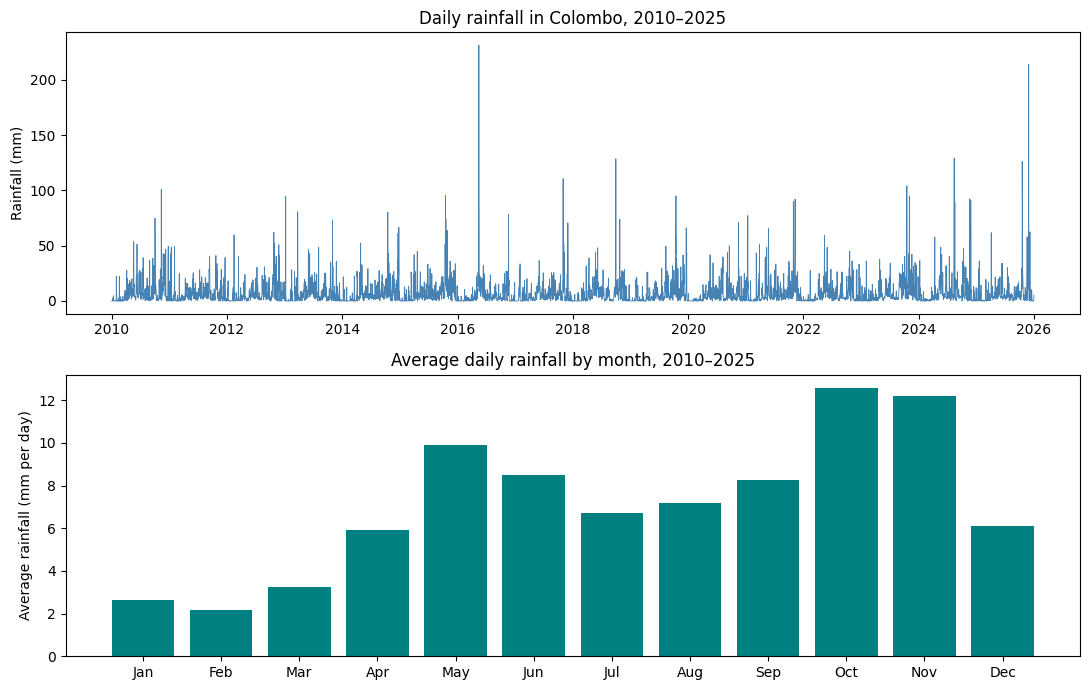

Median daily rainfall: 3.5 mm
Wettest day: 15 May 2016 (231.4 mm)
Highest monthly average: October (12.57 mm per day)


In [3]:
import matplotlib.pyplot as plt
import calendar

# Use the date as the index so we can plot rainfall over time.
daily = weather.set_index("date").sort_index()

# Group all January days together, all February days together, and so on.
monthly_average = daily.groupby(daily.index.month)["rain_mm"].mean()
month_names = [calendar.month_abbr[m] for m in monthly_average.index]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

# Chart 1: One rainfall value for each day.
axes[0].plot(daily.index, daily["rain_mm"], color="steelblue", linewidth=0.6)
axes[0].set_title("Daily rainfall in Colombo, 2010–2025")
axes[0].set_ylabel("Rainfall (mm)")

# Chart 2: One bar for each month's average daily rainfall.
axes[1].bar(month_names, monthly_average, color="teal")
axes[1].set_title("Average daily rainfall by month, 2010–2025")
axes[1].set_ylabel("Average rainfall (mm per day)")

plt.tight_layout()
plt.show()

print(f"Median daily rainfall: {daily['rain_mm'].median():.1f} mm")
print(f"Wettest day: {daily['rain_mm'].idxmax():%d %B %Y} "
      f"({daily['rain_mm'].max():.1f} mm)")
print(f"Highest monthly average: {calendar.month_name[monthly_average.idxmax()]} "
      f"({monthly_average.max():.2f} mm per day)")

The first chart shows that most days had much less rain than the wettest day. The median daily rainfall was 3.5 mm, while the highest daily rainfall was 231.4 mm on 15 May 2016.

The second chart shows that October had the highest average daily rainfall across 2010–2025 at 12.57 mm per day, followed by November at 12.22 mm per day.

## Step 3 — Preparing the prediction table and testing a baseline forecast

In [5]:
from sklearn.metrics import mean_absolute_error

table = daily.asfreq("D").copy()

# For each forecast date, look up rain from 1, 2, 3 and 7 days earlier.
for lag in [1, 2, 3, 7]:
    table[f"rain_lag_{lag}"] = table["rain_mm"].shift(lag)

# Average rainfall over the seven days BEFORE the forecast date.
table["rain_avg_7d"] = table["rain_mm"].shift(1).rolling(7).mean()

# Use the previous day's temperature and wind.
for column in ["max_temp_c", "min_temp_c", "max_wind_kmh"]:
    table[f"previous_{column}"] = table[column].shift(1)

table["month"] = table.index.month

# These are the inputs the ML models will use later.
features = [
    "rain_lag_1", "rain_lag_2", "rain_lag_3", "rain_lag_7",
    "rain_avg_7d", "previous_max_temp_c", "previous_min_temp_c",
    "previous_max_wind_kmh", "month",
]

# rain_mm is the answer we want to predict for each date.
model_data = table[features + ["rain_mm"]].dropna()

# Keep the dates in chronological order.
train = model_data.loc[:"2023-12-31"]
validation = model_data.loc["2024"]
test = model_data.loc["2025"]

print("Training days:", len(train))
print("Validation days:", len(validation))
print("Test days:", len(test))

# Show how yesterday's rain becomes the forecast for today.
preview = validation[["rain_lag_1", "rain_mm"]].head(3).copy()
preview.columns = ["Baseline forecast (mm)", "Actual rainfall (mm)"]
display(preview)

# Score the baseline on every day of 2024.
baseline_mae = mean_absolute_error(validation["rain_mm"], validation["rain_lag_1"])
print(f"Baseline validation MAE: {baseline_mae:.2f} mm")

Training days: 5106
Validation days: 366
Test days: 365


,Baseline forecast (mm),Actual rainfall (mm)
date,,
2024-01-01,20.8,21.2
2024-01-02,21.2,4.6
2024-01-03,4.6,0.6


Baseline validation MAE: 6.73 mm


Using the previous day’s rainfall as the forecast gave a mean absolute error (MAE) of 6.73 mm across the 366 days of 2024. This means the forecast differed from the archived rainfall by 6.73 mm per day on average. I will use this as the reference when comparing the trained models.


## Step 4A — Training and evaluating Random Forest

In [6]:
from time import perf_counter
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Create a forest with 100 decision trees.
rf = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)

# Train on 2010–2023 and record how long training takes.
start = perf_counter()
rf.fit(train[features], train["rain_mm"])
rf_training_seconds = perf_counter() - start

# Predict rainfall for the same 2024 dates used to evaluate the baseline.
rf_predictions = rf.predict(validation[features])
rf_mae = mean_absolute_error(validation["rain_mm"], rf_predictions)

print(f"Baseline validation MAE:      {baseline_mae:.2f} mm")
print(f"Random Forest validation MAE: {rf_mae:.2f} mm")
print(f"Reduction in MAE:             {baseline_mae - rf_mae:.2f} mm")
print(f"Training time:                {rf_training_seconds:.2f} seconds")

Baseline validation MAE:      6.73 mm
Random Forest validation MAE: 6.25 mm
Reduction in MAE:             0.49 mm
Training time:                3.28 seconds


Random Forest achieved a validation MAE of 6.25 mm across the 366 days of 2024. Using previous rainfall, temperature, wind and the calendar month reduced the average forecast error by about 0.49 mm compared with simply predicting the previous day’s rainfall.

## Step 4B — Training and evaluating the Bagging Regressor

In [7]:
from time import perf_counter
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(min_samples_leaf=5),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
)

# Train on the same 2010–2023 data used for Random Forest.
start = perf_counter()
bagging.fit(train[features], train["rain_mm"])
bagging_training_seconds = perf_counter() - start

# Evaluate on all 366 validation days in 2024.
bagging_predictions = bagging.predict(validation[features])
bagging_mae = mean_absolute_error(validation["rain_mm"], bagging_predictions)

print(f"Baseline validation MAE:      {baseline_mae:.3f} mm")
print(f"Random Forest validation MAE: {rf_mae:.3f} mm")
print(f"Bagging validation MAE:       {bagging_mae:.3f} mm")
print(f"Bagging training time:        {bagging_training_seconds:.2f} seconds")

Baseline validation MAE:      6.734 mm
Random Forest validation MAE: 6.247 mm
Bagging validation MAE:       6.241 mm
Bagging training time:        5.89 seconds


The Bagging Regressor achieved a validation MAE of 6.241 mm, improving on the previous-day rainfall baseline by about 0.49 mm. Random Forest achieved 6.247 mm, so the two ensemble models performed almost identically on the 2024 validation data.

## Step 4C — Comparing XGBoost, LightGBM and CatBoost

In [8]:
%pip install -q xgboost lightgbm catboost

In [9]:
import numpy as np
import pandas as pd
from time import perf_counter
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

boosting_models = {
    "XGBoost": XGBRegressor(
        n_estimators=150, max_depth=3, learning_rate=0.05,
        objective="reg:squarederror", random_state=42, n_jobs=2
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=150, max_depth=3, num_leaves=8, learning_rate=0.05,
        random_state=42, n_jobs=2, verbosity=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=150, depth=3, learning_rate=0.05,
        random_seed=42, thread_count=2, verbose=False, allow_writing_files=False
    ),
}

# Start with your three existing validation results.
validation_scores = {
    "Previous-day baseline": baseline_mae,
    "Random Forest": rf_mae,
    "Bagging Regressor": bagging_mae,
}
training_times = {
    "Previous-day baseline": 0.0,  # This rule needs no training.
    "Random Forest": rf_training_seconds,
    "Bagging Regressor": bagging_training_seconds,
}
boosting_predictions = {}

for name, model in boosting_models.items():
    start = perf_counter()
    model.fit(train[features], train["rain_mm"])
    training_times[name] = perf_counter() - start

    # Rainfall cannot be negative, so set any negative forecast to zero.
    predictions = np.maximum(model.predict(validation[features]), 0)
    boosting_predictions[name] = predictions
    validation_scores[name] = mean_absolute_error(validation["rain_mm"], predictions)

validation_results = pd.DataFrame({
    "2024 validation MAE (mm)": validation_scores,
    "Training time (seconds)": training_times,
}).sort_values("2024 validation MAE (mm)")

display(validation_results.round(3))

,2024 validation MAE (mm),Training time (seconds)
XGBoost,6.130,0.438
LightGBM,6.171,0.207
CatBoost,6.187,0.314
Bagging Regressor,6.241,5.886
Random Forest,6.247,3.278
Previous-day baseline,6.734,0.000


All three boosting models had lower average rainfall forecast errors than Bagging and Random Forest across the 366 validation days. XGBoost had the lowest MAE at 6.130 mm, improving on Bagging by 0.111 mm and on the previous-day baseline by 0.604 mm. LightGBM trained fastest in this run (0.207 seconds), and its MAE was only 0.041 mm higher than XGBoost’s.

## Step 4D — Combining five rainfall forecasts using stacking

In [10]:
from sklearn.linear_model import Ridge

# Each row is a day in 2024. Each column is one model's forecast for that day.
stack_inputs_2024 = pd.DataFrame(
    {
        "Random Forest": rf_predictions,
        "Bagging Regressor": bagging_predictions,
        **boosting_predictions,
    },
    index=validation.index,
)

# Learn how to combine the five forecasts using archived 2024 rainfall.
stack_model = Ridge(alpha=1.0)
start = perf_counter()
stack_model.fit(stack_inputs_2024, validation["rain_mm"])
ridge_training_seconds = perf_counter() - start

# Record the total fitting time for the five base models plus Ridge.
training_times["Stacking"] = (
    sum(training_times[name] for name in stack_inputs_2024.columns)
    + ridge_training_seconds
)

print("Days and model forecasts:", stack_inputs_2024.shape)
print(f"Ridge fitting time: {ridge_training_seconds:.4f} seconds")

# Preview what Ridge learned from: five forecasts and the answer for each date.
preview = stack_inputs_2024.head(3).copy()
preview["Archived rainfall (mm)"] = validation.loc[preview.index, "rain_mm"]
display(preview.round(2))

Days and model forecasts: (366, 5)
Ridge fitting time: 0.0326 seconds


,Random Forest,Bagging Regressor,XGBoost,LightGBM,CatBoost,Archived rainfall (mm)
date,,,,,,
2024-01-01,15.47,14.81,14.84,13.28,13.26,21.2
2024-01-02,14.28,13.28,11.95,11.11,13.27,4.6
2024-01-03,7.38,7.15,5.95,5.69,6.31,0.6


I trained Ridge regression to combine the daily forecasts from Random Forest, Bagging, XGBoost, LightGBM and CatBoost. Ridge learned from 366 days of forecasts and archived rainfall in 2024. I will compare stacking with XGBoost on the 365 days of 2025 to see whether combining the forecasts reduces the average error.


## Step 4E — ARIMA and the ARIMA + Random Forest hybrid

In [11]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from time import perf_counter

# Fit ARIMA on the same training dates used for the other models.
train_rain = train["rain_mm"].asfreq("D")
validation_rain = validation["rain_mm"].asfreq("D")

start = perf_counter()
arima_model = ARIMA(train_rain, order=(1, 0, 0)).fit()
training_times["ARIMA"] = perf_counter() - start

# For each 2024 day, predict from earlier rainfall, then update the
# history with that day's archived value. ARIMA's parameters stay fixed.
arima_through_2024 = arima_model.extend(validation_rain)
arima_validation = arima_through_2024.fittedvalues.clip(lower=0)

# Positive residual = ARIMA predicted too little rain.
residuals_2024 = validation_rain - arima_validation
arima_mae = mean_absolute_error(validation_rain, arima_validation)

print(f"2024 one-day ARIMA forecasts: {len(arima_validation)}")
print(f"ARIMA validation MAE: {arima_mae:.3f} mm")
print(f"Previous-day baseline MAE: {baseline_mae:.3f} mm")

arima_preview = pd.DataFrame({
    "ARIMA forecast (mm)": arima_validation,
    "Archived rainfall (mm)": validation_rain,
    "Correction needed (mm)": residuals_2024,
})
display(arima_preview.head(3).round(2))

2024 one-day ARIMA forecasts: 366
ARIMA validation MAE: 6.676 mm
Previous-day baseline MAE: 6.734 mm


,ARIMA forecast (mm),Archived rainfall (mm),Correction needed (mm)
2024-01-01,12.96,21.2,8.24
2024-01-02,13.14,4.6,-8.54
2024-01-03,5.98,0.6,-5.38


I fitted ARIMA using rainfall through 2023 and generated one-day-ahead forecasts for 2024. I then trained a Random Forest to predict ARIMA’s errors using earlier rainfall, temperature, wind and the calendar month. On the 2025 test data, I will compare the hybrid with both ARIMA alone and Random Forest alone to see whether the correction improves the forecast.


In [12]:
from time import perf_counter
from sklearn.ensemble import RandomForestRegressor

# Use the same nine inputs as before, but predict ARIMA's error.
residual_forest = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1,
)

start = perf_counter()
residual_forest.fit(validation[features], residuals_2024)
residual_forest_seconds = perf_counter() - start

# Include both parts when reporting the hybrid's training time.
training_times["ARIMA + Random Forest"] = (
    training_times["ARIMA"] + residual_forest_seconds
)

print("Days used to train the correction model:", len(residuals_2024))
print("Weather inputs per day:", residual_forest.n_features_in_)
print(f"Correction model training time: {residual_forest_seconds:.2f} seconds")

Days used to train the correction model: 366
Weather inputs per day: 9
Correction model training time: 0.48 seconds


I trained a Random Forest on ARIMA’s daily forecast errors for 2024. The hybrid adds the forest’s predicted correction to ARIMA’s rainfall forecast. I will evaluate it on 2025 data to see whether it achieves a lower error than ARIMA alone and Random Forest alone.

## Step 5 — Comparing nine rainfall forecasting methods on the 2025 test data

In [13]:
import numpy as np
import pandas as pd

actual = test["rain_mm"].asfreq("D")
X_test = test[features]

# Start with the baseline and the five tree-based models.
forecasts = pd.DataFrame(index=test.index)
forecasts["Previous-day baseline"] = test["rain_lag_1"]
forecasts["Random Forest"] = rf.predict(X_test)
forecasts["Bagging Regressor"] = bagging.predict(X_test)

for name, model in boosting_models.items():
    forecasts[name] = np.maximum(model.predict(X_test), 0)

# Give Ridge the same five model columns, in the same order as in 2024.
stack_inputs_2025 = forecasts[stack_inputs_2024.columns]
forecasts["Stacking"] = np.maximum(stack_model.predict(stack_inputs_2025), 0)

# Continue from December 2024. Each daily ARIMA prediction uses rainfall
# through the previous day, then the model updates its history.
arima_2025 = arima_through_2024.extend(actual)
forecasts["ARIMA"] = arima_2025.fittedvalues.clip(lower=0)

# Apply the correction learned in 2024.
correction = residual_forest.predict(X_test)
forecasts["ARIMA + Random Forest"] = (forecasts["ARIMA"] + correction).clip(lower=0)

print("Test days and forecasting methods:", forecasts.shape)
print("Missing forecasts:", forecasts.isna().sum().sum())
display(forecasts.head(3).round(2))

Test days and forecasting methods: (365, 9)
Missing forecasts: 0


,Previous-day baseline,Random Forest,Bagging Regressor,XGBoost,LightGBM,CatBoost,Stacking,ARIMA,ARIMA + Random Forest
date,,,,,,,,,
2025-01-01,6.6,3.73,4.19,5.04,4.89,6.08,7.37,6.85,9.13
2025-01-02,9.4,7.48,6.80,7.96,7.96,8.67,9.21,8.05,8.40
2025-01-03,1.7,5.57,5.21,5.93,6.74,3.68,4.53,4.73,3.24


In [14]:
# Use the same wettest days for every model, including ties at the cutoff.
wet_cutoff = actual.quantile(0.90)
wet_days = actual >= wet_cutoff

# For each day and method, calculate forecast minus archived rainfall.
errors = forecasts.sub(actual, axis="index")

comparison = pd.DataFrame({
    "MAE (mm)": errors.abs().mean(),
    "RMSE (mm)": np.sqrt(errors.pow(2).mean()),
    "Wettest-days MAE (mm)": errors.loc[wet_days].abs().mean(),
    "Training time (seconds)": pd.Series(training_times),
}).sort_values("MAE (mm)")
comparison.index.name = "Model"

display(comparison.round(3))

print(f"Wettest-day cutoff: {wet_cutoff:.1f} mm")
print(f"Days at or above the cutoff: {wet_days.sum()}")
print("Lowest overall MAE:", comparison["MAE (mm)"].idxmin())
print("Lowest wettest-days MAE:", comparison["Wettest-days MAE (mm)"].idxmin())

# A positive difference means the hybrid reduced the average error.
mae = comparison["MAE (mm)"]
for name in ["ARIMA", "Random Forest"]:
    improvement = mae[name] - mae["ARIMA + Random Forest"]
    print(f"Hybrid MAE reduction compared with {name}: {improvement:+.3f} mm")

# Save full-precision results for the dashboard.
comparison.to_csv("model_comparison.csv")
predictions_2025 = forecasts.copy()
predictions_2025.insert(0, "Actual rainfall (mm)", actual)
predictions_2025.to_csv("predictions_2025.csv", index_label="date")

,MAE (mm),RMSE (mm),Wettest-days MAE (mm),Training time (seconds)
Model,,,,
CatBoost,5.955,15.135,28.502,0.314
Random Forest,6.018,15.542,27.979,3.278
LightGBM,6.030,15.574,28.642,0.207
XGBoost,6.045,14.990,28.832,0.438
Bagging Regressor,6.111,15.513,28.257,5.886
ARIMA + Random Forest,6.256,14.782,27.286,1.126
ARIMA,6.274,14.994,29.266,0.645
Stacking,6.390,15.322,27.656,10.155
Previous-day baseline,6.406,17.294,30.687,0.000


Wettest-day cutoff: 16.2 mm
Days at or above the cutoff: 38
Lowest overall MAE: CatBoost
Lowest wettest-days MAE: ARIMA + Random Forest
Hybrid MAE reduction compared with ARIMA: +0.018 mm
Hybrid MAE reduction compared with Random Forest: -0.237 mm


Across all 365 test days in 2025, CatBoost achieved the lowest MAE at 5.955 mm. It reduced the average daily error by 0.451 mm compared with the previous-day baseline. On the 38 wettest days, the ARIMA + Random Forest hybrid performed best, with an MAE of 27.286 mm. It also had the lowest overall RMSE (14.782 mm), a measure that gives more weight to large errors.

Across the full year, the hybrid improved on ARIMA alone by only 0.018 mm and had a higher MAE than Random Forest alone. Stacking also had a higher MAE than XGBoost (6.390 mm versus 6.045 mm). Combining models helped most on the wettest days, while CatBoost gave the best average daily forecast.

## Step 6 — Explaining rainfall forecasts

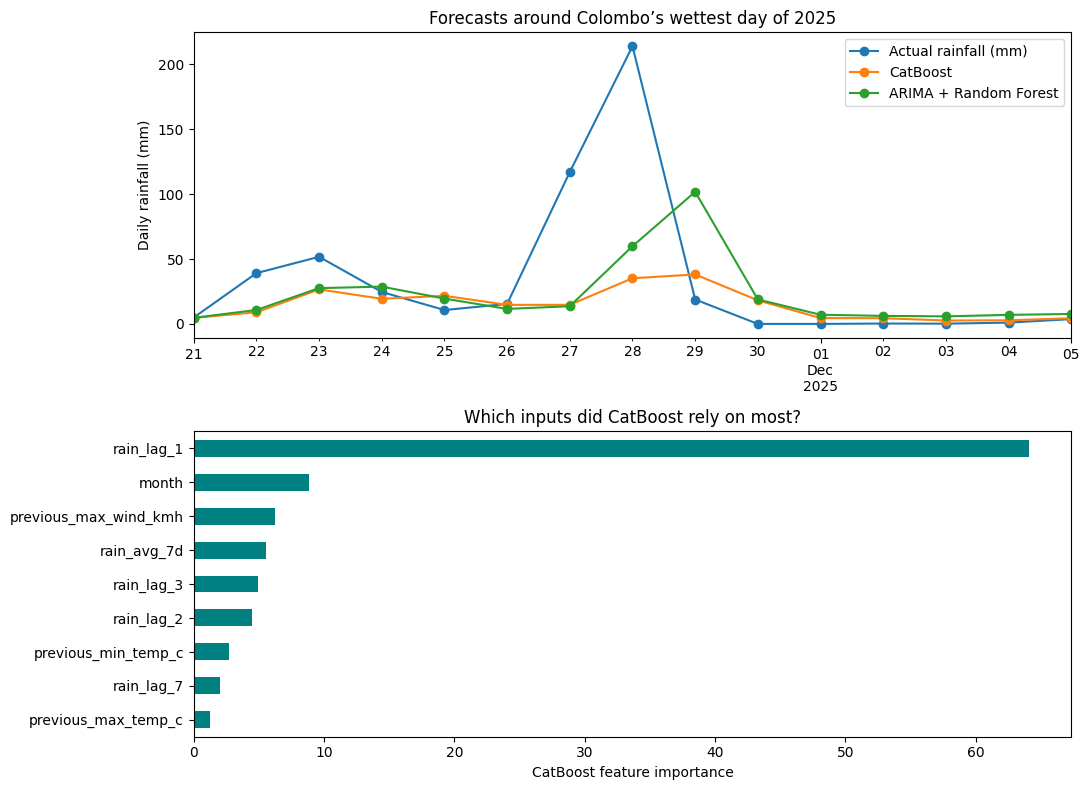

Wettest date: 2025-11-28
Actual rainfall (mm)     213.90
CatBoost                  35.18
ARIMA + Random Forest     59.82
Name: 2025-11-28 00:00:00, dtype: float64
Highest-ranked input: rain_lag_1


In [15]:
import matplotlib.pyplot as plt
import pandas as pd

hybrid = "ARIMA + Random Forest"
wettest_date = actual.idxmax()

# Show the week before and after the wettest day.
start_date = wettest_date - pd.Timedelta(days=7)
end_date = wettest_date + pd.Timedelta(days=7)
window = predictions_2025.loc[start_date:end_date]

# Use the CatBoost model already trained in Step 4C.
catboost_model = boosting_models["CatBoost"]
importance = pd.Series(
    catboost_model.feature_importances_,
    index=features,
).sort_values()

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

window[["Actual rainfall (mm)", "CatBoost", hybrid]].plot(
    ax=axes[0], marker="o"
)
axes[0].set_title("Forecasts around Colombo’s wettest day of 2025")
axes[0].set_ylabel("Daily rainfall (mm)")
axes[0].set_xlabel("")

importance.plot.barh(ax=axes[1], color="teal")
axes[1].set_title("Which inputs did CatBoost rely on most?")
axes[1].set_xlabel("CatBoost feature importance")

plt.tight_layout()
plt.show()

print("Wettest date:", wettest_date.date())
print(predictions_2025.loc[
    wettest_date, ["Actual rainfall (mm)", "CatBoost", hybrid]
].round(2))
print("Highest-ranked input:", importance.idxmax())

On 28 November 2025, the archive reported 213.90 mm of rainfall in Colombo. CatBoost predicted 35.18 mm, while the ARIMA + Random Forest hybrid predicted 59.82 mm. The hybrid came closer, but it still underestimated the peak by 154.08 mm. Both models predicted more rain on 29 November, after the archived rainfall had already fallen sharply.

CatBoost ranked the previous day’s rainfall as its most important input, followed by the calendar month. This helps explain why a forecast based on recent weather can lag behind a sudden change in rainfall.

In [16]:
catboost_model.save_model("colombo_catboost.cbm")
print("Saved model with", len(catboost_model.feature_names_), "input features.")

Saved model with 9 input features.


## Step 7 — Colombo Rain Watch dashboard.

In [17]:
%pip install -q streamlit

In [19]:
%%writefile app.py
# Dashboard code generated with ChatGPT.
from pathlib import Path

import pandas as pd
import streamlit as st
from catboost import CatBoostRegressor

st.set_page_config(page_title="Colombo Rain Watch", layout="wide")
folder = Path(__file__).resolve().parent


@st.cache_data
def load_data():
    weather = pd.read_csv(
        folder / "colombo_weather_daily.csv", parse_dates=["date"]
    ).set_index("date").sort_index()
    scores = pd.read_csv(folder / "model_comparison.csv").set_index("Model")
    predictions = pd.read_csv(
        folder / "predictions_2025.csv", parse_dates=["date"]
    ).set_index("date").sort_index()
    return weather, scores, predictions


@st.cache_resource
def load_model():
    model = CatBoostRegressor()
    model.load_model(str(folder / "colombo_catboost.cbm"))
    return model


weather, scores, predictions = load_data()
model = load_model()

st.title("Colombo Rain Watch")
st.caption("One-day rainfall forecasts for Colombo, Sri Lanka · ERA5 via Open-Meteo")

compare, explore, predict = st.tabs(
    ["Compare models", "Explore a date", "Make a prediction"]
)

with compare:
    st.header("Which model forecast rainfall best in 2025?")
    metric = st.selectbox(
        "Choose an error measure",
        ["MAE (mm)", "Wettest-days MAE (mm)", "RMSE (mm)"],
    )
    ranked = scores.sort_values(metric)
    st.metric(f"Lowest {metric} · {ranked.index[0]}", f"{ranked[metric].iloc[0]:.3f} mm")
    st.caption(
        "Lower values mean smaller errors. The full test covers 365 days. "
        "The wettest-days measure covers 38 days with at least 16.2 mm of rain."
    )
    st.bar_chart(ranked[metric], horizontal=True, sort=False)
    st.dataframe(ranked.round(3))

    with st.expander("View the weather dataset"):
        st.write(f"{len(weather):,} daily records from 2010 to 2025.")
        st.dataframe(weather.head(10))

with explore:
    st.header("Compare a forecast with archived rainfall")
    chosen = st.date_input(
        "Test date",
        value=pd.Timestamp("2025-11-28").date(),
        min_value=predictions.index.min().date(),
        max_value=predictions.index.max().date(),
    )
    day = pd.Timestamp(chosen)
    name = st.selectbox("Forecasting method", scores.index.tolist())
    row = predictions.loc[day]
    observed = row["Actual rainfall (mm)"]
    forecast = row[name]

    a, b, c = st.columns(3)
    a.metric("Archived rainfall", f"{observed:.2f} mm")
    b.metric("Forecast", f"{forecast:.2f} mm")
    c.metric("Absolute error", f"{abs(observed - forecast):.2f} mm")

    week = pd.Timedelta(days=7)
    st.line_chart(
        predictions.loc[day - week:day + week, ["Actual rainfall (mm)", name]],
        y_label="Rainfall (mm)",
    )

with predict:
    st.header("Make a CatBoost rainfall prediction")
    st.write(
        "Choose a historical forecast date. The form loads weather from earlier "
        "days. Change an input to see how the model’s forecast responds."
    )
    example = st.date_input(
        "Load example inputs for",
        value=pd.Timestamp("2025-11-28").date(),
        min_value=predictions.index.min().date(),
        max_value=predictions.index.max().date(),
    )
    target = pd.Timestamp(example)
    prior = weather.loc[weather.index < target].tail(7)

    defaults = {
        "rain_lag_1": prior["rain_mm"].iloc[-1],
        "rain_lag_2": prior["rain_mm"].iloc[-2],
        "rain_lag_3": prior["rain_mm"].iloc[-3],
        "rain_lag_7": prior["rain_mm"].iloc[-7],
        "rain_avg_7d": prior["rain_mm"].mean(),
        "previous_max_temp_c": prior["max_temp_c"].iloc[-1],
        "previous_min_temp_c": prior["min_temp_c"].iloc[-1],
        "previous_max_wind_kmh": prior["max_wind_kmh"].iloc[-1],
        "month": target.month,
    }
    labels = {
        "rain_lag_1": "Rain yesterday (mm)",
        "rain_lag_2": "Rain two days ago (mm)",
        "rain_lag_3": "Rain three days ago (mm)",
        "rain_lag_7": "Rain seven days ago (mm)",
        "rain_avg_7d": "Average rain over the previous seven days (mm/day)",
        "previous_max_temp_c": "Yesterday’s maximum temperature (°C)",
        "previous_min_temp_c": "Yesterday’s minimum temperature (°C)",
        "previous_max_wind_kmh": "Yesterday’s maximum wind speed (km/h)",
        "month": "Forecast month",
    }

    with st.form(f"forecast_{example}"):
        inputs = {}
        for feature in model.feature_names_:
            if feature == "month":
                inputs[feature] = st.number_input(
                    labels[feature], min_value=1, max_value=12, value=target.month
                )
            else:
                inputs[feature] = st.number_input(
                    labels[feature], value=float(defaults[feature]), format="%.3f"
                )
        submitted = st.form_submit_button("Predict rainfall")

    if submitted:
        if inputs["previous_min_temp_c"] > inputs["previous_max_temp_c"]:
            st.error("Minimum temperature must be at or below maximum temperature.")
        elif any(inputs[k] < 0 for k in inputs if k.startswith("rain_")
                 or k == "previous_max_wind_kmh"):
            st.error("Rainfall and wind speed must be zero or higher.")
        else:
            sample = pd.DataFrame([inputs], columns=model.feature_names_)
            estimate = max(0.0, float(model.predict(sample)[0]))
            st.metric("Predicted daily rainfall", f"{estimate:.2f} mm")

    st.subheader("Which inputs did CatBoost rely on most?")
    importance = pd.Series(
        model.get_feature_importance(),
        index=[labels[k] for k in model.feature_names_],
        name="Feature importance",
    ).sort_values(ascending=False)
    st.bar_chart(importance, horizontal=True, sort=False)

Overwriting app.py


In [21]:
from streamlit.testing.v1 import AppTest
from pathlib import Path
app_path = Path("app.py").resolve()
print("Testing dashboard at:", app_path)
app_test = AppTest.from_file(str(app_path)).run(timeout=60)
assert not app_test.exception, [e.message for e in app_test.exception]

app_test.button[0].click().run(timeout=60)
assert not app_test.exception, [e.message for e in app_test.exception]

result = next(m for m in app_test.metric if m.label == "Predicted daily rainfall")
print("Dashboard prediction:", result.value)
assert result.value == "35.18 mm"
print("Passed: the dashboard matches the notebook forecast.")

2026-11-21 15:05:31.177 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Testing dashboard at: /content/app.py
Dashboard prediction: 35.18 mm
Passed: the dashboard matches the notebook forecast.
